In [1]:
pip install osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 1.9 MB/s eta 0:00:00:00:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
import ee, time
import numpy as np, pandas as pd, requests

ee.Authenticate(auth_mode="notebook")      # link -> sign in -> paste code


To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=CJug74EqnREgDSFMGrhgHDudu5AZwQDbpsd2RG9Ve3A&tc=tnvRD6fqcnAvyzaq6wchNMNuP7eExtc1jsc05XBsc2E&cc=oMXg4yhXPBkNau_HgGuIw274UdlLLnigcyI4E36Tv_c

The authorization workflow will generate a code, which you should paste in the box below.


Enter verification code:  4/1AXlqoi6W9ERK88JDQIJypV35evRm-1hlGal7a7wnDzu1JB5XHi81QxlIrEU



Successfully saved authorization token.


In [3]:
ee.Initialize(project="fluent-cinema-476712-c1")
print("Earth Engine ready")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Earth Engine ready


In [4]:
CITIES = {
    "delhi":     {"bbox": [76.85, 28.40, 77.40, 28.90]},   # [west, south, east, north]
    "prayagraj": {"bbox": [81.70, 25.35, 82.00, 25.55]},
    "jaipur":    {"bbox": [75.68, 26.80, 75.92, 27.00]},
    "lucknow":   {"bbox": [80.85, 26.75, 81.08, 26.95]},
    "jamshedpur":{"bbox": [86.12, 22.74, 86.28, 22.87]},
}
DATE_START, DATE_END = "2024-01-01", "2026-09-25"
MAX_CLOUD  = 20     # scene-level cloud %; raise to 20 if you get too few scenes
MAX_SCENES = 60
N_POINTS   = 3000
SEED       = 42

# ---- static layers (WorldCover, SRTM) ----
wc   = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
srtm = ee.Image("USGS/SRTMGL1_003")

def frac(mask, name):   # % of area inside a 100 m radius
    return mask.focalMean(radius=100, kernelType="circle", units="meters").multiply(100).rename(name)

def ctx(mask, r, name):
    return mask.focalMean(radius=r, kernelType="circle", units="meters").multiply(100).rename(name)

lowveg = wc.eq(20).Or(wc.eq(30)).Or(wc.eq(40))   # shrub, grass, crop
static = ee.Image.cat([
    wc.rename("landcover"),
    srtm.select("elevation"),
    ee.Terrain.slope(srtm).rename("slope"),
    frac(wc.eq(10), "pct_tree"),
    frac(wc.eq(50), "pct_built"),
    frac(wc.eq(80), "pct_water"),
    frac(lowveg,    "pct_lowveg"),
    ctx(wc.eq(50), 300,  "built_300"),
    ctx(wc.eq(50), 1000, "built_1000"),
    ctx(wc.eq(10), 300,  "tree_300"),
    ctx(wc.eq(80), 500,  "water_500"),
])

BANDS = ["lst_c", "st_qa", "ndvi", "ndbi", "ndwi", "landcover", "elevation",
         "slope", "pct_tree", "pct_built", "pct_water", "pct_lowveg",
         "built_300", "built_1000", "tree_300", "water_500"]

def prep(img):
    qa  = img.select("QA_PIXEL").bitwiseAnd(0b11111).eq(0)   # fill, dilated cloud, cirrus, cloud, shadow
    sat = img.select("QA_RADSAT").eq(0)
    sr  = img.select(["SR_B3", "SR_B4", "SR_B5", "SR_B6"]).multiply(0.0000275).add(-0.2)
    lst = img.select("ST_B10").multiply(0.00341802).add(149.0).subtract(273.15).rename("lst_c")
    st_qa = img.select("ST_QA").multiply(0.01).rename("st_qa")
    ndvi = sr.normalizedDifference(["SR_B5", "SR_B4"]).rename("ndvi")
    ndbi = sr.normalizedDifference(["SR_B6", "SR_B5"]).rename("ndbi")
    ndwi = sr.normalizedDifference(["SR_B3", "SR_B5"]).rename("ndwi")
    return ee.Image.cat([lst, st_qa, ndvi, ndbi, ndwi, static]).updateMask(qa.And(sat))

def scene_collection(box):
    return (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
            .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
            .filterBounds(box).filterDate(DATE_START, DATE_END)
            .filter(ee.Filter.lt("CLOUD_COVER", MAX_CLOUD))
            .sort("CLOUD_COVER").limit(MAX_SCENES))

def make_points(bbox, n, seed):
    rng = np.random.default_rng(seed)
    lon = rng.uniform(bbox[0], bbox[2], n)
    lat = rng.uniform(bbox[1], bbox[3], n)
    feats = [ee.Feature(ee.Geometry.Point([float(x), float(y)]), {"pixel_id": int(i)})
             for i, (x, y) in enumerate(zip(lon, lat))]
    return ee.FeatureCollection(feats), pd.DataFrame({"pixel_id": np.arange(n), "lat": lat, "lon": lon})

# ---- checkpoint: how many scenes per city? ----
for name, cfg in CITIES.items():
    box = ee.Geometry.Rectangle(cfg["bbox"])
    print(name, scene_collection(box).size().getInfo(), "scenes")

delhi 60 scenes
prayagraj 60 scenes
jaipur 60 scenes
lucknow 60 scenes
jamshedpur 60 scenes


In [5]:
import numpy as np, pandas as pd, lightgbm as lgb
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import spearmanr

# ----------------------------------------------------------
# Data
# ----------------------------------------------------------
df = pd.read_parquet('/kaggle/input/datasets/shauryapandey19/heatpathv3/heatpath_raw_v3.parquet')

# Spatial anomaly target — what the routing model actually uses
df["lst_anom"] = df["lst_c"] - df.groupby("scene_id")["lst_c"].transform("mean")

# ----------------------------------------------------------
# Feature sets
# ----------------------------------------------------------
WX   = ["air_temp","humidity","wind_speed","wind_dir","radiation","cloud_cover_wx",
        "overpass_hour","sun_elevation","doy",
        "air_temp_lag1","air_temp_lag3","air_temp_lag6","radiation_lag1","radiation_lag3"]
SURF = ["ndvi","ndbi","ndwi","landcover","elevation","slope"]
NBR  = ["pct_tree","pct_built","pct_water","pct_lowveg"]

SETS = {"weather_only": WX, "weather+surface": WX + SURF, "full": WX + SURF + NBR}

# The 7 surface features used by the shipped spatial-anomaly model
SP = ["ndvi","ndbi","ndwi","pct_tree","pct_built","pct_water","pct_lowveg",
      "built_300","built_1000","tree_300","water_500"]

PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)

# ----------------------------------------------------------
# Metrics
# ----------------------------------------------------------
def metrics_abs(d):
    """Absolute-temperature metrics: overall fit + within-scene spatial fit."""
    y, p = d["lst_c"], d["p"]
    yc = y - d.groupby("scene_id")["lst_c"].transform("mean")
    pc = p - d.groupby("scene_id")["p"].transform("mean")
    return dict(R2=r2_score(y, p),
                MAE=mean_absolute_error(y, p),
                R2_within=r2_score(yc, pc))

def metrics_anom(d):
    """Spatial-anomaly metrics: how well hot/cool spots are ranked."""
    y, p = d["lst_anom"], d["p"]
    sp = np.nanmean([spearmanr(g["lst_anom"], g["p"])[0]
                     for _, g in d.groupby("scene_id")])
    return dict(R2=r2_score(y, p),
                MAE=mean_absolute_error(y, p),
                spearman=sp)

# ----------------------------------------------------------
# CV — block AND scene held out (no leakage from either)
# ----------------------------------------------------------
def block_scene_cv(feats, target="lst_c", k=5, seed=0):
    rng = np.random.default_rng(seed)
    bmap = dict(zip(df.block_id.unique(), rng.integers(0, k, df.block_id.nunique())))
    smap = dict(zip(df.scene_id.unique(), rng.integers(0, k, df.scene_id.nunique())))
    fb, fs = df.block_id.map(bmap).values, df.scene_id.map(smap).values

    pred = np.full(len(df), np.nan)
    for f in range(k):
        te = (fb == f) & (fs == f)
        tr = (fb != f) & (fs != f)
        m = lgb.LGBMRegressor(**PARAMS).fit(df.loc[tr, feats], df.loc[tr, target])
        pred[te] = m.predict(df.loc[te, feats])

    ok = ~np.isnan(pred)
    out = df.loc[ok].copy()
    out["p"] = pred[ok]
    return out

# ----------------------------------------------------------
# Cross-city transfer
# ----------------------------------------------------------
def transfer(feats, src, dst, target="lst_c"):
    tr = df[df.city == src]
    te = df[df.city == dst].copy()
    m = lgb.LGBMRegressor(**PARAMS).fit(tr[feats], tr[target])
    te["p"] = m.predict(te[feats])
    return te

# ==========================================================
# TRACK A — absolute temperature (weather signal)
# ==========================================================
print("=" * 72)
print("TRACK A — Absolute temperature (lst_c)")
print("=" * 72)

rows = []
for name, f in SETS.items():
    cv = block_scene_cv(f, target="lst_c")
    rows.append({"set": name, "test": "block+scene CV", **metrics_abs(cv)})

print(pd.DataFrame(rows).round(3).to_string(index=False))

# ==========================================================
# TRACK B — spatial anomaly (the model the app uses)
# ==========================================================
print("\n" + "=" * 72)
print("TRACK B — Spatial anomaly (lst_anom) — surface features only")
print("=" * 72)

cv = block_scene_cv(SP, target="lst_anom")
print("block+scene CV  :", {k: round(v, 3) for k, v in metrics_anom(cv).items()})

# ==========================================================
# TRACK C — cross-city transfer of the anomaly model
# ==========================================================
print("\n" + "=" * 72)
print("TRACK C — Cross-city transfer (spatial anomaly, surface-only)")
print("=" * 72)

TRAIN_CITIES = sorted(df.city.unique())
# Test cities = any city NOT used as source in a given row.
# For real 'unseen city' claims, the test city must NOT be in the training set.
TRANSFER_PAIRS = [(s, d) for s in TRAIN_CITIES for d in TRAIN_CITIES if s != d]

rows = []
for src, dst in TRANSFER_PAIRS:
    te = transfer(SP, src, dst, target="lst_anom")
    rows.append({"train": src, "test": dst, **metrics_anom(te)})

transfer_tab = pd.DataFrame(rows).round(3)
print(transfer_tab.to_string(index=False))

# Pivot for readability: rows = train city, cols = test city
print("\nSpearman (within-scene) by train → test:")
print(transfer_tab.pivot(index="train", columns="test", values="spearman").round(3))

TRACK A — Absolute temperature (lst_c)
            set           test    R2   MAE  R2_within
   weather_only block+scene CV 0.674 3.585      0.000
weather+surface block+scene CV 0.787 2.858      0.521
           full block+scene CV 0.798 2.762      0.569

TRACK B — Spatial anomaly (lst_anom) — surface features only
block+scene CV  : {'R2': 0.484, 'MAE': 1.296, 'spearman': np.float64(0.624)}

TRACK C — Cross-city transfer (spatial anomaly, surface-only)
     train       test     R2   MAE  spearman
   bangkok      delhi -0.253 2.810     0.240
   bangkok      dhaka -0.121 1.582     0.478
   bangkok     jaipur -0.449 2.507    -0.022
   bangkok jamshedpur -0.384 2.320     0.575
   bangkok    karachi  0.141 1.987     0.121
   bangkok     lahore -0.079 1.415     0.274
   bangkok    lucknow -0.587 1.818     0.237
   bangkok  prayagraj -0.723 3.030     0.240
     delhi    bangkok  0.338 1.743     0.515
     delhi      dhaka  0.111 1.423     0.604
     delhi     jaipur  0.202 1.857     0.672
   

In [6]:
ks, tes = [], []
CITIES_TR = sorted(df.city.unique())
for c in CITIES_TR:
    tr, te = df[df.city != c], df[df.city == c].copy()
    m = lgb.LGBMRegressor(**PARAMS).fit(tr[SP], tr["lst_anom"])
    te["p"] = m.predict(te[SP])
    te["p"] -= te.groupby("scene_id")["p"].transform("mean")
    te["y"] = te["lst_anom"] - te.groupby("scene_id")["lst_anom"].transform("mean")
    ks.append(np.polyfit(te.p, te.y, 1)[0]); tes.append(te)
K = float(np.median(ks))
for c, te in zip(CITIES_TR, tes):
    print(c, "| R2 raw", round(r2_score(te.y, te.p), 3), "-> with K", round(r2_score(te.y, K * te.p), 3))
print("K =", round(K, 2))

bangkok | R2 raw 0.464 -> with K 0.47
delhi | R2 raw 0.438 -> with K 0.449
dhaka | R2 raw 0.429 -> with K 0.413
jaipur | R2 raw 0.439 -> with K 0.445
jamshedpur | R2 raw 0.549 -> with K 0.542
karachi | R2 raw 0.561 -> with K 0.56
lahore | R2 raw 0.277 -> with K 0.281
lucknow | R2 raw 0.525 -> with K 0.526
prayagraj | R2 raw 0.305 -> with K 0.289
K = 1.05


In [7]:
SP7 = ["ndvi","ndbi","ndwi","pct_tree","pct_built","pct_water","pct_lowveg"]

def loco(feats):
    out = {}
    for c in sorted(df.city.unique()):
        tr, te = df[df.city != c], df[df.city == c].copy()
        m = lgb.LGBMRegressor(**PARAMS).fit(tr[feats], tr["lst_anom"])
        te["p"] = m.predict(te[feats])
        out[c] = np.nanmean([spearmanr(g.lst_anom, g.p)[0] for _, g in te.groupby("scene_id")])
    return pd.Series(out)

cmp = pd.DataFrame({"7 features": loco(SP7), "11 features": loco(SP)})
cmp.loc["mean"] = cmp.mean()
print(cmp.round(3))

            7 features  11 features
bangkok          0.514        0.506
delhi            0.683        0.672
dhaka            0.620        0.576
jaipur           0.605        0.613
jamshedpur       0.710        0.710
karachi          0.521        0.538
lahore           0.435        0.344
lucknow          0.639        0.635
prayagraj        0.692        0.577
mean             0.602        0.575


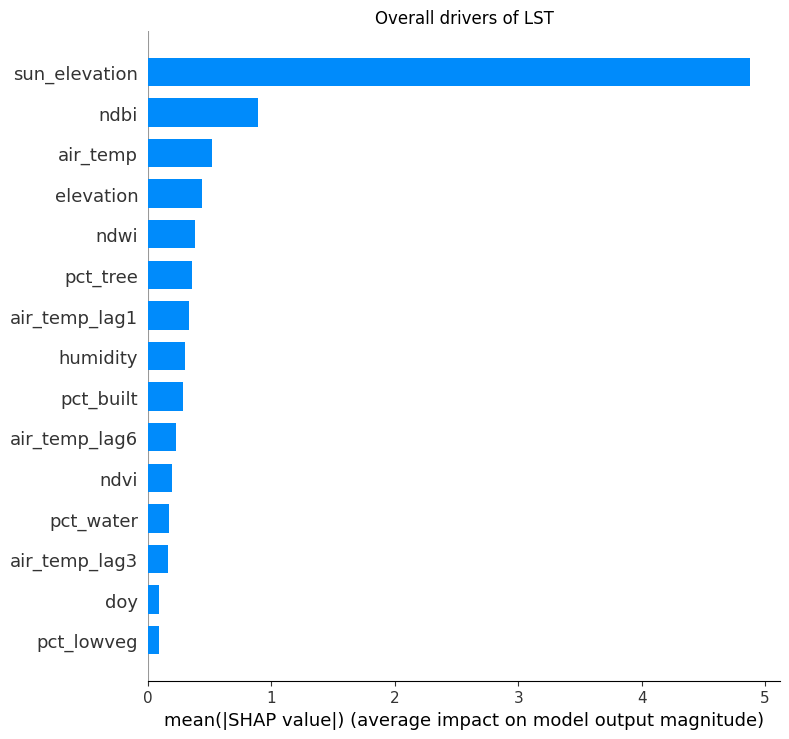

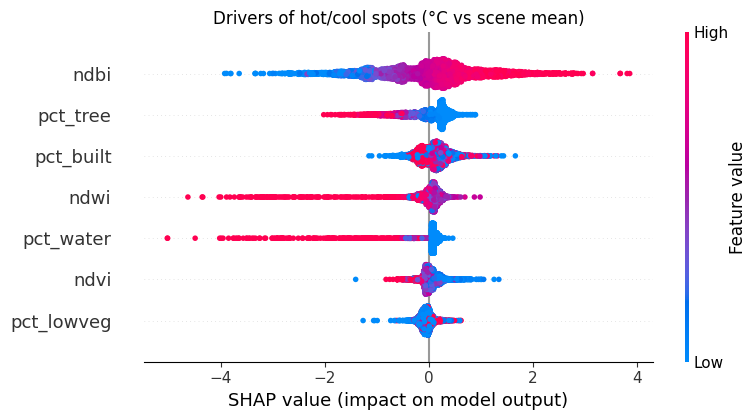

In [8]:
import shap, matplotlib.pyplot as plt

S = df.sample(5000, random_state=0)

# 1) Full model: what drives LST overall (weather will dominate: hot days vs cool days)
F = WX + SURF + NBR
m1 = lgb.LGBMRegressor(**PARAMS).fit(df[F], df["lst_c"])
sv1 = shap.TreeExplainer(m1).shap_values(S[F])
shap.summary_plot(sv1, S[F], plot_type="bar", max_display=15, show=False)
plt.title("Overall drivers of LST"); plt.tight_layout(); plt.show()

# 2) Spatial model: what makes a spot hotter or cooler than the city average that day
df["lst_anom"] = df["lst_c"] - df.groupby("scene_id")["lst_c"].transform("mean")
SP7 = ["ndvi","ndbi","ndwi","pct_tree","pct_built","pct_water","pct_lowveg"]
m2 = lgb.LGBMRegressor(**PARAMS).fit(df[SP7], df["lst_anom"])
sv2 = shap.TreeExplainer(m2).shap_values(S[SP7])
shap.summary_plot(sv2, S[SP7], max_display=10, show=False)
plt.title("Drivers of hot/cool spots (°C vs scene mean)"); plt.tight_layout(); plt.show()

In [9]:


DEMO = {
    "gorakhpur": [83.30, 26.70, 83.46, 26.82],
    "kolkata":   [88.27, 22.46, 88.45, 22.65],
}

STEP_M, N_SCENES, CHUNK = 100, 3, 3000
SP = ["ndvi","ndbi","ndwi","pct_tree","pct_built","pct_water","pct_lowveg",
      "built_300","built_1000","tree_300","water_500"]


# ---------- final spatial model ----------
# Trained on the 5 training cities only. Test cities stay unseen.
assert not {"ahmedabad", "gorakhpur", "kolkata"} & set(df.city.unique()), "test city in training"
model = lgb.LGBMRegressor(**PARAMS).fit(df[SP], df["lst_anom"])

print("Final spatial model trained on:", sorted(df["city"].unique()))
print("Features:", SP)


# ---------- grid + sampling ----------
def make_grid(bbox, step_m):
    w, s, e, n = bbox

    dlat = step_m / 111320.0
    dlon = step_m / (111320.0 * np.cos(np.radians((s + n) / 2)))

    lons = np.arange(w + dlon / 2, e, dlon)
    lats = np.arange(s + dlat / 2, n, dlat)

    LON, LAT = np.meshgrid(lons, lats)

    g = pd.DataFrame({
        "cell_id": np.arange(LON.size),
        "lon": LON.ravel(),
        "lat": LAT.ravel()
    })

    return g, (len(lats), len(lons))


def sample_scene(raw, pts):
    proj = raw.select("ST_B10").projection()

    # EXACT SAME surface-feature pipeline as training
    img = prep(raw).select(SP)

    rows = []

    for k in range(0, len(pts), CHUNK):

        g = pts.iloc[k:k + CHUNK]

        fc = ee.FeatureCollection([
            ee.Feature(
                ee.Geometry.Point([float(x), float(y)]),
                {"cell_id": int(i)}
            )
            for i, x, y in zip(g.cell_id, g.lon, g.lat)
        ])

        res = None

        for attempt in range(3):
            try:
                res = img.sampleRegions(
                    collection=fc,
                    properties=["cell_id"],
                    scale=30,
                    projection=proj
                ).getInfo()
                break
            except Exception as e:
                print("  retry:", str(e)[:100])
                time.sleep(5)

        if res is None:
            raise RuntimeError("A chunk failed after 3 tries; rerun the cell.")

        rows += [f["properties"] for f in res["features"]]

    return pd.DataFrame(rows)


def pick_scenes(bbox, grid, n=N_SCENES, max_try=12):

    col = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
        .filterBounds(ee.Geometry.Rectangle(bbox))
        .filterDate(DATE_START, DATE_END)
        .filter(ee.Filter.eq("PROCESSING_LEVEL", "L2SP"))
        .filter(ee.Filter.calendarRange(3, 6, "month"))
        .filter(ee.Filter.lt("CLOUD_COVER", MAX_CLOUD))
        .sort("CLOUD_COVER")
    )

    m = min(col.size().getInfo(), max_try)
    lst = col.toList(m)
    probe = grid.sample(400, random_state=0)
    chosen = []

    for i in range(m):

        raw = ee.Image(lst.get(i))
        frac = len(sample_scene(raw, probe)) / len(probe)

        print(f"  candidate {raw.get('system:index').getInfo()}: {frac:.0%} valid")

        if frac >= 0.85:
            chosen.append(raw)

        if len(chosen) == n:
            break

    return chosen

Final spatial model trained on: ['bangkok', 'delhi', 'dhaka', 'jaipur', 'jamshedpur', 'karachi', 'lahore', 'lucknow', 'prayagraj']
Features: ['ndvi', 'ndbi', 'ndwi', 'pct_tree', 'pct_built', 'pct_water', 'pct_lowveg', 'built_300', 'built_1000', 'tree_300', 'water_500']


ahmedabad 20008 cells
  candidate 1_LC08_148044_20240423: 100% valid
  candidate 1_LC08_148044_20250309: 100% valid
  candidate 1_LC08_148044_20250325: 100% valid
1_LC08_148044_20240423: level 47.3 °C | spearman 0.46 | R2 0.40 | MAE 1.71 °C


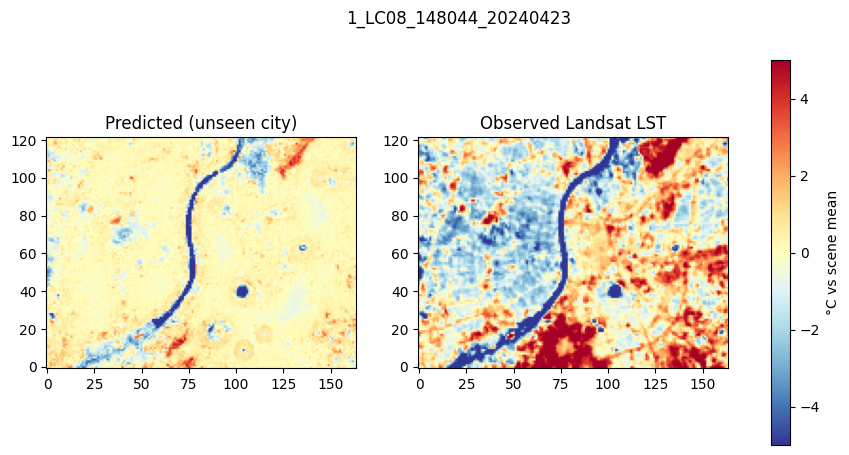

1_LC08_148044_20250309: level 40.3 °C | spearman 0.42 | R2 0.43 | MAE 1.33 °C


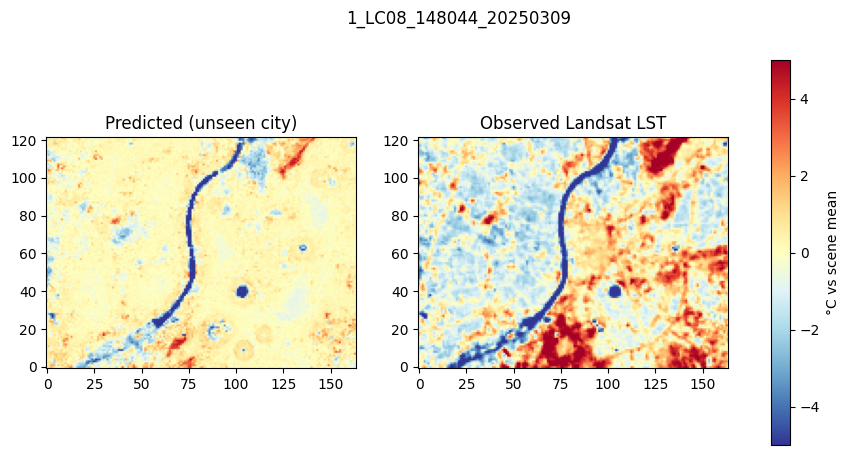

1_LC08_148044_20250325: level 44.5 °C | spearman 0.43 | R2 0.43 | MAE 1.54 °C


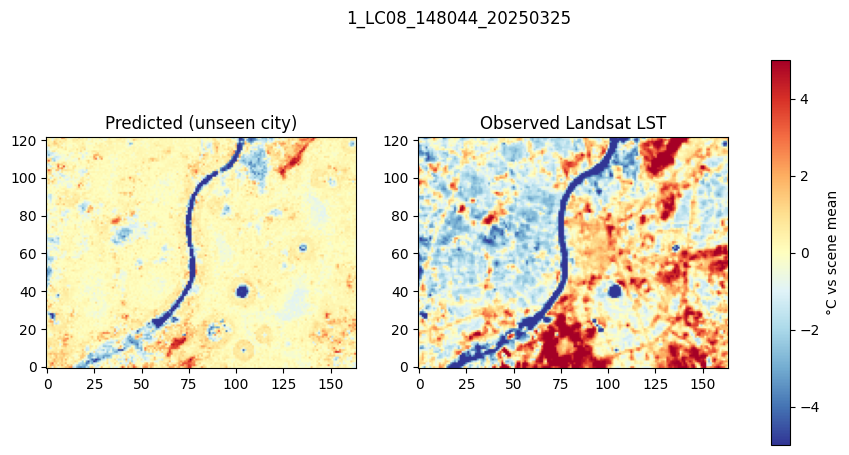

cells with no data: 0.0


In [10]:

from scipy.stats import spearmanr
AHM_DEMO = [72.50, 22.97, 72.66, 23.08]          # [W,S,E,N] city core
BANDS = SP + ["lst_c"]

def sample_bands(raw, pts, bands):
    proj = raw.select("ST_B10").projection()
    img = prep(raw).select(bands)
    rows = []
    for k in range(0, len(pts), CHUNK):
        g = pts.iloc[k:k + CHUNK]
        fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(x), float(y)]), {"cell_id": int(i)})
                                   for i, x, y in zip(g.cell_id, g.lon, g.lat)])
        res = None
        for attempt in range(3):
            try:
                res = img.sampleRegions(collection=fc, properties=["cell_id"], scale=30, projection=proj).getInfo()
                break
            except Exception as e:
                print("  retry:", str(e)[:100]); time.sleep(5)
        if res is None:
            raise RuntimeError("a chunk failed after 3 tries; rerun the cell")
        rows += [f["properties"] for f in res["features"]]
    return pd.DataFrame(rows)

grid, (nlat, nlon) = make_grid(AHM_DEMO, STEP_M)
print("ahmedabad", len(grid), "cells")
frames = []
for raw in pick_scenes(AHM_DEMO, grid):
    d = sample_bands(raw, grid, BANDS)
    d = d[d.lst_c.between(-5, 75)].copy()
    sid = raw.get("system:index").getInfo()

    p = model.predict(d[SP])                         # model never saw Ahmedabad
    d["pred"] = K * (p - p.mean())                        # both centred over the SAME cells
    d["obs"]  = d.lst_c - d.lst_c.mean()
    d["heat_c"] = d.lst_c.mean() + d["pred"]         # real °C level + predicted pattern

    print(f"{sid}: level {d.lst_c.mean():.1f} °C | spearman {spearmanr(d.obs, d.pred)[0]:.2f} | "
          f"R2 {r2_score(d.obs, d.pred):.2f} | MAE {mean_absolute_error(d.obs, d.pred):.2f} °C")

    fig, ax = plt.subplots(1, 2, figsize=(11, 5))
    for a, col, t in zip(ax, ["pred", "obs"], ["Predicted (unseen city)", "Observed Landsat LST"]):
        z = np.full(nlat * nlon, np.nan); z[d.cell_id.values] = d[col].values
        im = a.imshow(z.reshape(nlat, nlon), origin="lower", cmap="RdYlBu_r", vmin=-5, vmax=5)
        a.set_title(t)
    fig.colorbar(im, ax=ax, label="°C vs scene mean"); plt.suptitle(sid); plt.show()
    frames.append(d[["cell_id", "pred", "heat_c", "pct_tree", "pct_water", "pct_built"]])

assert frames, "no usable scene: set MAX_CLOUD = 20 and rerun"
agg = (pd.concat(frames).groupby("cell_id")
       .agg(heat_anom=("pred", "mean"), heat_c=("heat_c", "mean"), n_obs=("pred", "size"),
            pct_tree=("pct_tree", "mean"), pct_water=("pct_water", "mean"),
            pct_built=("pct_built", "mean")).reset_index())
out = grid.merge(agg, on="cell_id", how="left")
out["n_obs"] = out["n_obs"].fillna(0).astype(int)
out.to_parquet("/kaggle/working/heat_grid_ahmedabad.parquet", index=False)
print("cells with no data:", round((out.n_obs == 0).mean(), 3))


=== gorakhpur ===
  candidate 1_LC08_142042_20250331: 100% valid
  candidate 1_LC08_142042_20260521: 100% valid
  candidate 2_LC09_142041_20250424: 100% valid
1_LC08_142042_20250331: level 39.0 °C | spearman 0.60 | R2 0.50 | MAE 1.28 °C | slope 1.20
1_LC08_142042_20260521: level 37.7 °C | spearman 0.77 | R2 0.70 | MAE 0.91 °C | slope 1.01
2_LC09_142041_20250424: level 44.2 °C | spearman 0.70 | R2 0.50 | MAE 1.67 °C | slope 1.13
saved heat_grid_gorakhpur.parquet | no data: 0.0 | multi-scene spearman: 0.72

=== kolkata ===
  candidate 1_LC08_138045_20240401: 74% valid
  candidate 2_LC09_138044_20250327: 100% valid
  candidate 2_LC09_138045_20250311: 70% valid
  candidate 1_LC08_138044_20240401: 100% valid
  candidate 2_LC09_138044_20240308: 100% valid
2_LC09_138044_20250327: level 39.6 °C | spearman 0.76 | R2 0.69 | MAE 1.42 °C | slope 1.34
1_LC08_138044_20240401: level 40.9 °C | spearman 0.75 | R2 0.67 | MAE 1.40 °C | slope 1.30
2_LC09_138044_20240308: level 32.9 °C | spearman 0.72 | R

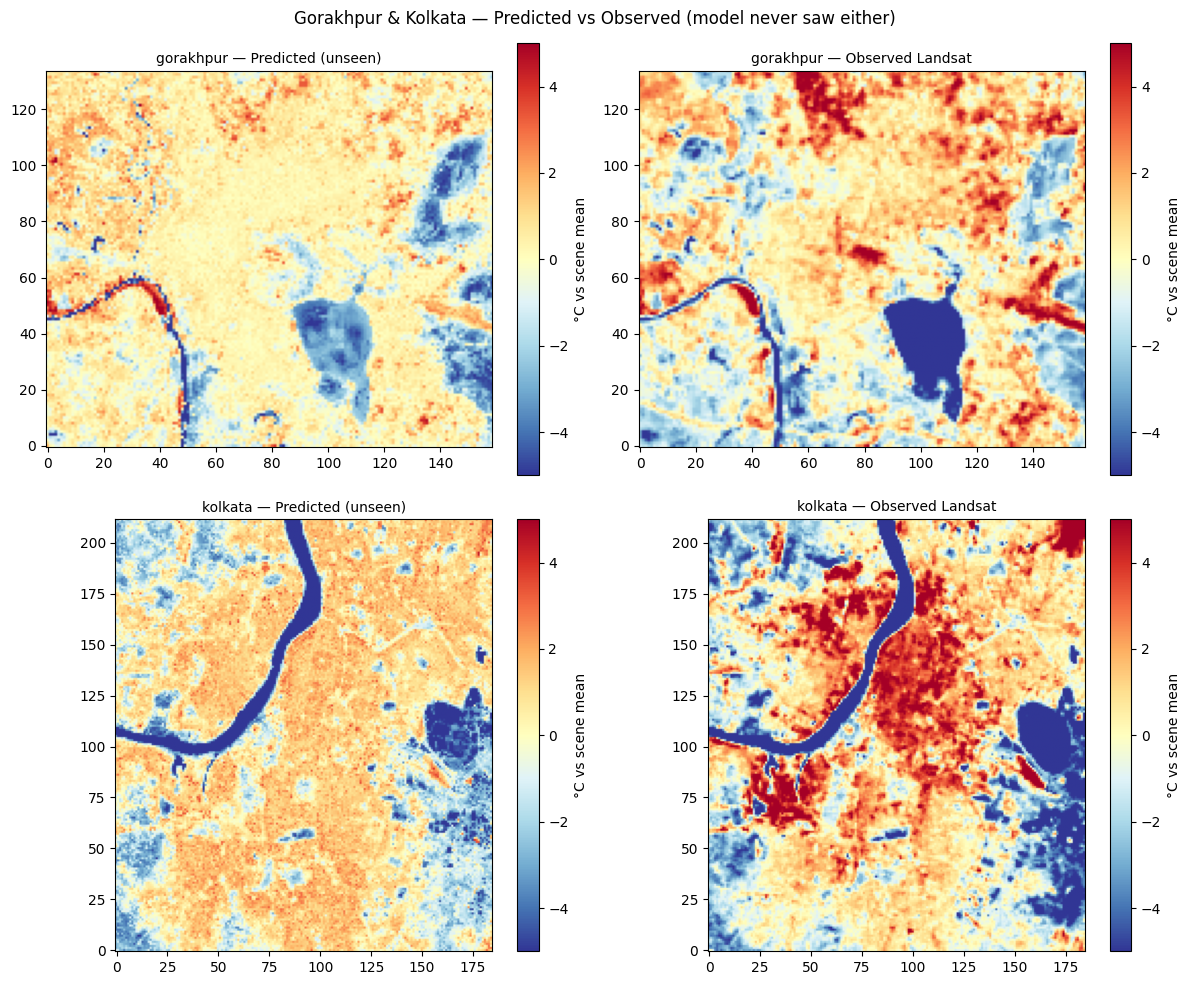


Per-scene transfer metrics:

[gorakhpur]
                 scene  level_C  spearman    R2  MAE_C  slope
1_LC08_142042_20250331   38.952     0.602 0.504  1.279  1.203
1_LC08_142042_20260521   37.710     0.767 0.700  0.911  1.010
2_LC09_142041_20250424   44.157     0.702 0.504  1.673  1.132

[kolkata]
                 scene  level_C  spearman    R2  MAE_C  slope
2_LC09_138044_20250327   39.582     0.759 0.695  1.416  1.337
1_LC08_138044_20240401   40.865     0.754 0.669  1.405  1.304
2_LC09_138044_20240308   32.930     0.718 0.657  1.272  1.096


In [11]:


DEMO_TEST = {
    "gorakhpur": [83.30, 26.70, 83.46, 26.82],
    "kolkata":   [88.27, 22.46, 88.45, 22.65],
}
BANDS = SP + ["lst_c"]

def sample_bands(raw, pts, bands):
    proj = raw.select("ST_B10").projection()
    img  = prep(raw).select(bands)
    rows = []
    for k in range(0, len(pts), CHUNK):
        g  = pts.iloc[k:k + CHUNK]
        fc = ee.FeatureCollection([
            ee.Feature(ee.Geometry.Point([float(x), float(y)]), {"cell_id": int(i)})
            for i, x, y in zip(g.cell_id, g.lon, g.lat)])
        res = None
        for attempt in range(3):
            try:
                res = img.sampleRegions(collection=fc, properties=["cell_id"],
                                        scale=30, projection=proj).getInfo()
                break
            except Exception as e:
                print("  retry:", str(e)[:100]); time.sleep(5)
        if res is None:
            raise RuntimeError("a chunk failed after 3 tries; rerun the cell")
        rows += [f["properties"] for f in res["features"]]
    return pd.DataFrame(rows)

results, CAPTURE = {}, {}

for city, bbox in DEMO_TEST.items():
    print(f"\n=== {city} ===")
    grid, (nlat, nlon) = make_grid(bbox, STEP_M)
    frames, per_scene = [], []

    for raw in pick_scenes(bbox, grid):
        d = sample_bands(raw, grid, BANDS)
        d = d[d.lst_c.between(-5, 75)].copy()
        if d.empty:
            continue
        sid = raw.get("system:index").getInfo()

        p = model.predict(d[SP])
        d["pred"]   = K * (p - p.mean())
        d["obs"]    = d.lst_c - d.lst_c.mean()
        d["heat_c"] = d.lst_c.mean() + d["pred"]

        rho   = spearmanr(d.obs, d.pred)[0]
        r2    = r2_score(d.obs, d.pred)
        ma    = mean_absolute_error(d.obs, d.pred)
        slope = np.polyfit(d.pred, d.obs, 1)[0]
        print(f"{sid}: level {d.lst_c.mean():.1f} °C | spearman {rho:.2f} | R2 {r2:.2f} | "
              f"MAE {ma:.2f} °C | slope {slope:.2f}")
        per_scene.append({"scene": sid, "level_C": d.lst_c.mean(),
                          "spearman": rho, "R2": r2, "MAE_C": ma, "slope": slope})

        if city not in CAPTURE:
            CAPTURE[city] = (d.copy(), nlat, nlon, sid)
        frames.append(d[["cell_id", "pred", "obs", "heat_c", "pct_tree", "pct_water", "pct_built"]])

    assert frames, f"no usable scene for {city}: raise MAX_CLOUD and rerun"

    agg = (pd.concat(frames).groupby("cell_id")
           .agg(heat_anom=("pred", "mean"), obs=("obs", "mean"), heat_c=("heat_c", "mean"),
                n_obs=("pred", "size"), pct_tree=("pct_tree", "mean"),
                pct_water=("pct_water", "mean"), pct_built=("pct_built", "mean"))
           .reset_index())
    out = grid.merge(agg, on="cell_id", how="left")
    out["n_obs"] = out["n_obs"].fillna(0).astype(int)
    out.to_parquet(f"/kaggle/working/heat_grid_{city}.parquet", index=False)

    ok = out.dropna(subset=["heat_anom", "obs"])
    print(f"saved heat_grid_{city}.parquet | no data: {round((out.n_obs == 0).mean(), 3)} | "
          f"multi-scene spearman: {round(spearmanr(ok.heat_anom, ok.obs)[0], 2)}")
    results[city] = {"per_scene": pd.DataFrame(per_scene)}

cities = list(CAPTURE.keys())
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for row, city in enumerate(cities):
    d, nlat, nlon, sid = CAPTURE[city]
    for col, (colname, title) in enumerate([("pred", f"{city} — Predicted (unseen)"),
                                            ("obs",  f"{city} — Observed Landsat")]):
        ax = axes[row, col]
        z = np.full(nlat * nlon, np.nan)
        z[d.cell_id.values] = d[colname].values
        im = ax.imshow(z.reshape(nlat, nlon), origin="lower", cmap="RdYlBu_r", vmin=-5, vmax=5)
        ax.set_title(title, fontsize=10)
        fig.colorbar(im, ax=ax, label="°C vs scene mean", fraction=0.046)
plt.suptitle("Gorakhpur & Kolkata — Predicted vs Observed (model never saw either)", fontsize=12)
plt.tight_layout(); plt.show()

print("\nPer-scene transfer metrics:")
for city, r in results.items():
    print(f"\n[{city}]")
    print(r["per_scene"].round(3).to_string(index=False))


KOLKATA
retry: 'overpass.kumi.systems' responded: 500 Internal Server Error <!DOCTYPE HTML PUBLIC "-//W3C//DTD HTML
26909 nodes | 67367 edges
         minutes     km  exposure  mean_temp  extra_min  extra_%  exposure_cut_%  cooler_C
fastest    23.34   5.84     13.83       1.34       0.00     0.00            0.00      0.00
λ=1        24.42   6.10      8.59       0.92       1.08     4.61           37.87      0.42
λ=3        24.87   6.22      8.29       0.90       1.53     6.55           40.08      0.45
λ=10       25.03   6.26      8.25       0.90       1.68     7.20           40.37      0.44
λ=30       42.23  10.56      6.83       0.35      18.89    80.93           50.64      0.99

kolkata recommended (λ=10): +1.7 min (+7%), 0.44 °C cooler, exposure cut 40%


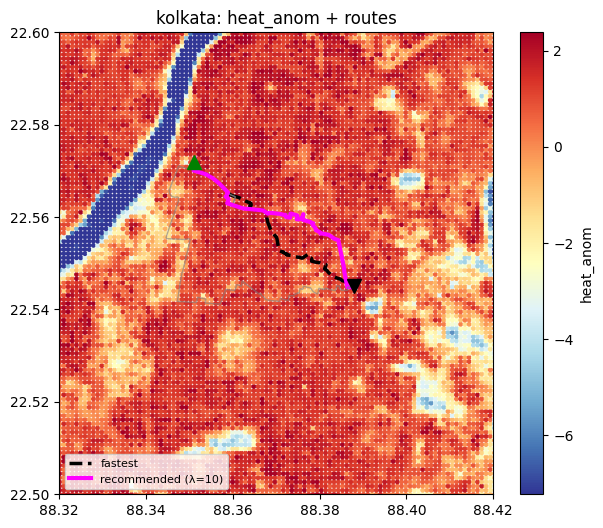

saved: kolkata_roads_scored.pkl + kolkata_route_table.csv

GORAKHPUR
12988 nodes | 31322 edges
         minutes    km  exposure  mean_temp  extra_min  extra_%  exposure_cut_%  cooler_C
fastest    20.33  5.08      1.31      -0.26       0.00     0.00            0.00      0.00
λ=3        21.99  5.50      0.75      -0.39       1.66     8.18           42.84      0.13
λ=100      25.84  6.46      0.68      -0.43       5.51    27.12           48.19      0.17

gorakhpur recommended (λ=3): +1.7 min (+8%), 0.13 °C cooler, exposure cut 43%


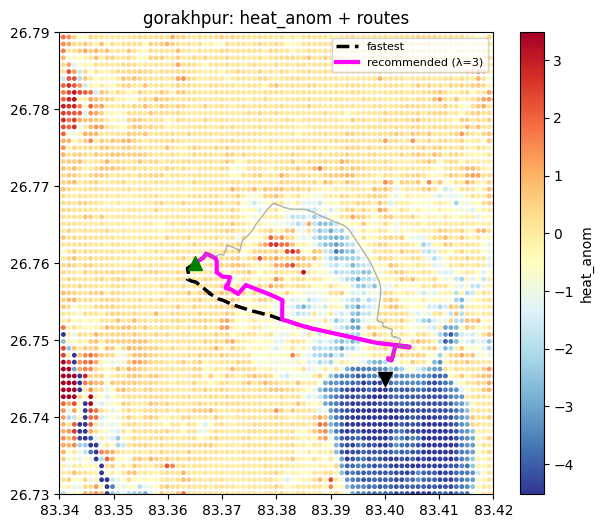

saved: gorakhpur_roads_scored.pkl + gorakhpur_route_table.csv


In [12]:
import osmnx as ox
from scipy.spatial import cKDTree
import time, pickle, networkx as nx
from shapely.geometry import LineString

assert int(ox.__version__.split(".")[0]) >= 2, "need osmnx>=2"

# ---------- settings (shared) ----------
MODE, SPEED_KMH = "bike", 15
HEAT_COL        = "heat_anom"
STEP_M, SAMPLE_M = 100, 20
LAMBDAS    = [1, 3, 10, 30, 100]
MAX_DETOUR = 0.25

# ---------- per-city configs ----------
CITY_CFG = {
    "kolkata": {
        "route_bbox": [88.32, 22.50, 88.42, 22.60],
        "orig": (88.351, 22.572),
        "dest": (88.388, 22.545),
    },
    "gorakhpur": {
        "route_bbox": [83.34, 26.73, 83.42, 26.79],
        "orig": (83.365, 26.760),
        "dest": (83.400, 26.745),
    },
}

# ---------- helper functions ----------
def to_xy(lon, lat, lat0):
    return np.c_[np.asarray(lon) * 111320 * np.cos(np.radians(lat0)),
                 np.asarray(lat) * 111320]

def best_edge(G, a, b, wt):
    return min(G[a][b].values(), key=lambda x: x[wt])

def evaluate(G, src, dst, wt):
    nodes = nx.shortest_path(G, src, dst, weight=wt)
    t = E_ = TH = L = 0.0
    for a, b in zip(nodes[:-1], nodes[1:]):
        e = best_edge(G, a, b, wt)
        t += e["t"]; E_ += e["E"]; TH += e["th"]; L += e["length"]
    return nodes, dict(minutes=t, km=L / 1000, exposure=E_, mean_temp=TH / t)

def route_xy(G, nodes, wt):
    X, Y = [], []
    for a, b in zip(nodes[:-1], nodes[1:]):
        e = best_edge(G, a, b, wt)
        if "geometry" in e:
            gx, gy = map(list, e["geometry"].xy)
            ax_, ay_ = G.nodes[a]["x"], G.nodes[a]["y"]
            if (gx[0]-ax_)**2 + (gy[0]-ay_)**2 > (gx[-1]-ax_)**2 + (gy[-1]-ay_)**2:
                gx, gy = gx[::-1], gy[::-1]
        else:
            gx, gy = [G.nodes[a]["x"], G.nodes[b]["x"]], [G.nodes[a]["y"], G.nodes[b]["y"]]
        X += gx; Y += gy
    return X, Y

MIRRORS = ["https://overpass.kumi.systems/api", "https://overpass-api.de/api",
           "https://overpass.private.coffee/api"]
ox.settings.overpass_rate_limit = False
ox.settings.timeout = 300
ox.settings.requests_timeout = 300


# ============================================================
# MAIN LOOP — one full routing run per city
# ============================================================
for CITY, cfg in CITY_CFG.items():
    print(f"\n{'='*60}\n{CITY.upper()}\n{'='*60}")

    ROUTE_BBOX = cfg["route_bbox"]
    ORIG, DEST = cfg["orig"], cfg["dest"]

    # ---------- 1) heat grid -> fast lookup ----------
    hg   = pd.read_parquet(f"/kaggle/working/heat_grid_{CITY}.parquet")
    lat0 = hg.lat.mean()
    h    = hg[HEAT_COL].fillna(hg[HEAT_COL].median()).to_numpy()
    REF  = np.percentile(h, 50)
    tree = cKDTree(to_xy(hg.lon, hg.lat, lat0))
    west, south, east, north = ROUTE_BBOX
    assert west >= hg.lon.min() and east <= hg.lon.max() and \
           south >= hg.lat.min() and north <= hg.lat.max(), \
        f"{CITY}: ROUTE_BBOX must be inside the heat grid"

    # ---------- 2) road graph ----------
    G = None
    for attempt in range(6):
        ox.settings.overpass_url = MIRRORS[attempt % len(MIRRORS)]
        try:
            G = ox.graph_from_bbox(tuple(ROUTE_BBOX), network_type=MODE); break
        except Exception as e:
            print("retry:", str(e)[:100]); time.sleep(10)
    assert G is not None, f"{CITY}: Overpass failed on all mirrors"
    G = ox.truncate.largest_component(G, strongly=True)
    print(len(G.nodes), "nodes |", len(G.edges), "edges")

    # ---------- 3) heat per road segment ----------
    edges = list(G.edges(keys=True, data=True))
    eid, px, py = [], [], []
    for i, (u, v, k, ed) in enumerate(edges):
        geom = ed["geometry"] if "geometry" in ed else LineString(
            [(G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"])])
        n = max(1, int(np.ceil(ed["length"] / SAMPLE_M)))
        for f in (np.arange(n) + 0.5) / n:
            p = geom.interpolate(f, normalized=True)
            eid.append(i); px.append(p.x); py.append(p.y)

    dist, idx = tree.query(to_xy(px, py, lat0))
    near = dist <= 1.5 * STEP_M
    hp   = np.where(near, h[idx], np.nan)
    sp   = np.where(near, np.clip(h[idx] - REF, 0, None), np.nan)
    eid  = np.array(eid)
    s_edge = pd.Series(sp).groupby(eid).mean()
    h_edge = pd.Series(hp).groupby(eid).mean()
    s_fill, h_fill = np.nanmedian(sp), np.nanmedian(hp)

    v_m_min = SPEED_KMH * 1000 / 60
    for i, (u, v, k, ed) in enumerate(edges):
        s = s_edge.get(i, np.nan); s = s_fill if np.isnan(s) else s
        t   = ed["length"] / v_m_min
        h_e = h_edge.get(i, np.nan); h_e = h_fill if np.isnan(h_e) else h_e
        ed["t"], ed["E"], ed["th"] = t, t * s, t * h_e
        ed["c0"] = t
        for j, lam in enumerate(LAMBDAS, 1):
            ed[f"c{j}"] = t * (1 + lam * s)

    # ---------- 4) routes ----------
    src = ox.distance.nearest_nodes(G, ORIG[0], ORIG[1])
    dst = ox.distance.nearest_nodes(G, DEST[0], DEST[1])
    assert src != dst, f"{CITY}: ORIG and DEST snap to the same node"

    cands = {"fastest": "c0", **{f"λ={l}": f"c{j}" for j, l in enumerate(LAMBDAS, 1)}}
    routes, seen = {}, set()
    for name, wt in cands.items():
        nodes, m = evaluate(G, src, dst, wt)
        if tuple(nodes) in seen: continue
        seen.add(tuple(nodes)); routes[name] = (nodes, m, wt)

    tab  = pd.DataFrame({k: m for k, (n, m, w) in routes.items()}).T
    base = tab.loc["fastest"]
    tab["extra_min"]      = tab.minutes - base.minutes
    tab["extra_%"]        = 100 * (tab.minutes / base.minutes - 1)
    tab["exposure_cut_%"] = 100 * (1 - tab.exposure / base.exposure)
    tab["cooler_C"]       = base.mean_temp - tab.mean_temp
    print(tab.round(2).to_string())

    allowed = tab[tab["extra_%"] <= 100 * MAX_DETOUR]
    best    = allowed["exposure"].idxmin()
    r = tab.loc[best]
    if best == "fastest":
        print(f"\n{CITY}: no cooler route within the detour cap.")
    else:
        print(f"\n{CITY} recommended ({best}): +{r.extra_min:.1f} min "
              f"(+{r['extra_%']:.0f}%), {r.cooler_C:.2f} °C cooler, "
              f"exposure cut {r['exposure_cut_%']:.0f}%")

    # ---------- 5) plot ----------
    fig, ax = plt.subplots(figsize=(7, 6))
    lo, hi = np.percentile(h, [2, 98])
    sc = ax.scatter(hg.lon, hg.lat, c=h, s=6, cmap="RdYlBu_r", vmin=lo, vmax=hi)
    for name, (nodes, m, wt) in routes.items():
        X, Y = route_xy(G, nodes, wt)
        if name == "fastest":  ax.plot(X, Y, "k--", lw=2.5, label="fastest")
        elif name == best:     ax.plot(X, Y, color="magenta", lw=3, label=f"recommended ({name})")
        else:                  ax.plot(X, Y, color="grey", lw=1, alpha=.6)
    ax.plot(*ORIG, "g^", ms=10); ax.plot(*DEST, "kv", ms=10)
    ax.set_xlim(west, east); ax.set_ylim(south, north)
    ax.set_title(f"{CITY}: {HEAT_COL} + routes")
    ax.legend(fontsize=8)
    plt.colorbar(sc, label=HEAT_COL); plt.show()

    # ---------- 6) save ----------
    pickle.dump(G, open(f"/kaggle/working/{CITY}_roads_scored.pkl", "wb"))
    tab.to_csv(f"/kaggle/working/{CITY}_route_table.csv")
    print(f"saved: {CITY}_roads_scored.pkl + {CITY}_route_table.csv")


BIKANER
13098 cells
  candidate 1_LC08_149040_20240516: 100% valid
  candidate 1_LC08_149040_20240617: 100% valid
  candidate 1_LC08_149040_20250401: 100% valid
1_LC08_149040_20240516: level 52.7 °C | spearman 0.81 | R2 0.57 | MAE 1.90 °C | slope 0.40
1_LC08_149040_20240617: level 55.4 °C | spearman 0.83 | R2 0.55 | MAE 1.81 °C | slope 0.39
1_LC08_149040_20250401: level 44.7 °C | spearman 0.79 | R2 0.52 | MAE 2.09 °C | slope 0.37
  multi-scene: spearman 0.833 | R2 0.572 | MAE 1.85 °C | slope 0.40
  saved heat_grid_bikaner.parquet | no data: 0.0

RAIPUR
19430 cells
  candidate 1_LC08_142045_20250315: 100% valid
  candidate 1_LC08_142045_20260302: 100% valid
  candidate 1_LC08_142046_20240328: 6% valid
  candidate 1_LC08_142046_20240531: 6% valid
  candidate 1_LC08_143045_20250306: 4% valid
  candidate 1_LC08_143045_20250423: 13% valid
  candidate 1_LC08_143045_20260309: 2% valid
  candidate 2_LC09_142045_20240405: 100% valid
1_LC08_142045_20250315: level 40.7 °C | spearman 0.62 | R2 0.

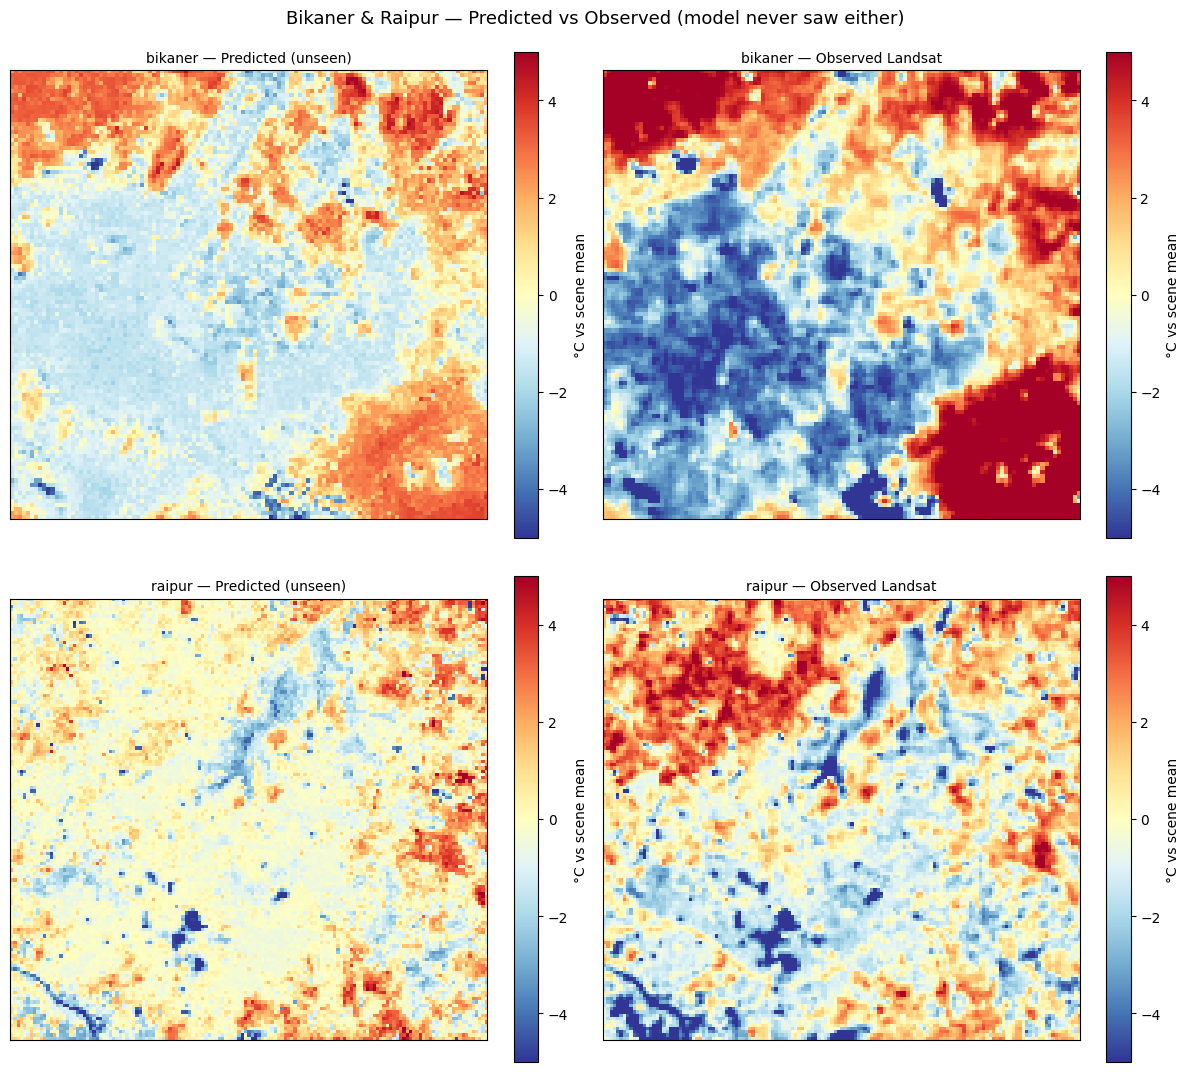

In [13]:
TEST_CITIES = {
    "bikaner": [73.28, 27.98, 73.40, 28.08],   # [W, S, E, N]  — hot desert
    "raipur":  [81.58, 21.20, 81.72, 21.32],   # central India — semi-arid hot
}

BANDS = SP + ["lst_c"]


def sample_bands(raw, pts, bands):
    proj = raw.select("ST_B10").projection()
    img  = prep(raw).select(bands)
    rows = []
    for k in range(0, len(pts), CHUNK):
        g  = pts.iloc[k:k + CHUNK]
        fc = ee.FeatureCollection([
            ee.Feature(ee.Geometry.Point([float(x), float(y)]), {"cell_id": int(i)})
            for i, x, y in zip(g.cell_id, g.lon, g.lat)
        ])
        res = None
        for attempt in range(3):
            try:
                res = img.sampleRegions(collection=fc, properties=["cell_id"],
                                        scale=30, projection=proj).getInfo()
                break
            except Exception as e:
                print("  retry:", str(e)[:100]); time.sleep(5)
        if res is None:
            raise RuntimeError("a chunk failed after 3 tries; rerun the cell")
        rows += [f["properties"] for f in res["features"]]
    return pd.DataFrame(rows)


# ---------- collect, predict, save grid, capture first scene for plot ----------
CAPTURE   = {}   # city -> (d, nlat, nlon, sid)  for the plot
PER_SCENE = []   # rows for the metrics table

for city, bbox in TEST_CITIES.items():
    print(f"\n{'='*60}\n{city.upper()}\n{'='*60}")

    grid, (nlat, nlon) = make_grid(bbox, STEP_M)
    print(f"{len(grid)} cells")

    frames = []
    for raw in pick_scenes(bbox, grid, n=3):
        d = sample_bands(raw, grid, BANDS)
        d = d[d.lst_c.between(-5, 75)].copy()
        if d.empty:
            continue
        sid = raw.get("system:index").getInfo()

        p = model.predict(d[SP])              # model never saw this city
        d["pred"] = p - p.mean()                    # centred over same cells as obs
        d["obs"]  = d.lst_c - d.lst_c.mean()

        sp    = spearmanr(d.obs, d.pred)[0]
        r2    = r2_score(d.obs, d.pred)
        ma    = mean_absolute_error(d.obs, d.pred)
        slope = np.polyfit(d.obs, d.pred, 1)[0]

        print(f"{sid}: level {d.lst_c.mean():.1f} °C | "
              f"spearman {sp:.2f} | R2 {r2:.2f} | MAE {ma:.2f} °C | slope {slope:.2f}")
        PER_SCENE.append({"city": city, "scene": sid, "level_C": d.lst_c.mean(),
                          "spearman": sp, "R2": r2, "MAE_C": ma, "slope": slope})

        # keep an "obs anomaly" column for the multi-scene heat grid
        d["heat_anom"] = d["pred"]
        d["heat_c"]    = d["obs"]                    # so grid has both (temp + anomaly)
        frames.append(d[["cell_id","pred","obs","heat_anom","heat_c",
                         "pct_tree","pct_water","pct_built"]])

        if city not in CAPTURE:                       # first usable scene → plot
            CAPTURE[city] = (d.copy(), nlat, nlon, sid)

    if not frames:
        print(f"  !! no usable scene for {city}")
        continue

    # ---------- aggregate across scenes → heat grid ----------
    agg = (pd.concat(frames, ignore_index=True)
             .groupby("cell_id")
             .agg(heat_anom=("heat_anom","mean"),
                  heat_c   =("heat_c","mean"),
                  pred     =("pred","mean"),
                  obs      =("obs","mean"),
                  n_obs    =("heat_anom","size"),
                  pct_tree =("pct_tree","mean"),
                  pct_water=("pct_water","mean"),
                  pct_built=("pct_built","mean"))
             .reset_index())
    out = grid.merge(agg, on="cell_id", how="left")
    out["n_obs"] = out["n_obs"].fillna(0).astype(int)

    # multi-scene metrics on the pooled anomalies
    sp_m    = spearmanr(out.obs, out.pred)[0]
    r2_m    = r2_score(out.obs, out.pred)
    ma_m    = mean_absolute_error(out.obs, out.pred)
    slope_m = np.polyfit(out.obs, out.pred, 1)[0]
    print(f"  multi-scene: spearman {sp_m:.3f} | R2 {r2_m:.3f} | "
          f"MAE {ma_m:.2f} °C | slope {slope_m:.2f}")

    out.to_parquet(f"/kaggle/working/heat_grid_{city}.parquet", index=False)
    print(f"  saved heat_grid_{city}.parquet | "
          f"no data: {round((out.n_obs==0).mean(), 3)}")


# ---------- per-scene metrics table ----------
print("\nPer-scene transfer metrics:")
print(pd.DataFrame(PER_SCENE).round(3).to_string(index=False))


# ---------- 2 x 2 side-by-side figure ----------
cities = [c for c in TEST_CITIES if c in CAPTURE]
fig, axes = plt.subplots(len(cities), 2, figsize=(12, 5.5 * len(cities)))
if len(cities) == 1:
    axes = axes.reshape(1, -1)

for row, city in enumerate(cities):
    d, nlat, nlon, sid = CAPTURE[city]
    for col, (colname, title) in enumerate([
        ("pred", f"{city} — Predicted (unseen)"),
        ("obs",  f"{city} — Observed Landsat"),
    ]):
        ax = axes[row, col]
        z  = np.full(nlat * nlon, np.nan)
        z[d.cell_id.values] = d[colname].values
        im = ax.imshow(z.reshape(nlat, nlon), origin="lower",
                       cmap="RdYlBu_r", vmin=-5, vmax=5)
        ax.set_title(title, fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, label="°C vs scene mean", fraction=0.046)

plt.suptitle("Bikaner & Raipur — Predicted vs Observed (model never saw either)",
             fontsize=13)
plt.tight_layout()
plt.show()

In [14]:
import numpy as np, pandas as pd, networkx as nx, pickle

N_TRIPS, MIN_KM, MAX_KM, SEED = 100, 3, 7, 42
WTS = {"fastest": "c0", **{f"λ={l}": f"c{j}" for j, l in enumerate(LAMBDAS, 1)}}

def sample_trips(G, n, rng):
    nodes, trips = list(G.nodes), []
    while len(trips) < n:
        o = nodes[rng.integers(len(nodes))]
        d = nx.single_source_dijkstra_path_length(G, o, cutoff=MAX_KM * 1000, weight="length")
        c = [v for v, l in d.items() if l >= MIN_KM * 1000]      # fastest-route length in 3-7 km
        if c:
            trips.append((o, c[rng.integers(len(c))]))
    return trips

def run_trips(G, trips):
    rows = []
    for ti, (o, d) in enumerate(trips):
        _, base = evaluate(G, o, d, "c0")
        for name, wt in WTS.items():
            if name == "fastest":
                continue
            _, m = evaluate(G, o, d, wt)
            extra = 100 * (m["minutes"] / base["minutes"] - 1)
            ok = extra <= 100 * MAX_DETOUR + 1e-9
            rows.append(dict(
                trip=ti, route=name, E0=base["exposure"], ok=ok,
                E=m["exposure"] if ok else base["exposure"],           # over cap -> user gets fastest
                extra_min=(m["minutes"] - base["minutes"]) if ok else 0.0,
                cooler_C=(base["mean_temp"] - m["mean_temp"]) if ok else 0.0))
    return pd.DataFrame(rows)

def summarize(df, rng, B=2000):
    best = (df.sort_values(["trip", "E", "extra_min"]).groupby("trip").head(1)
              .assign(route="best_per_trip", ok=True))               # your demo logic: min exposure within cap
    df = pd.concat([df, best], ignore_index=True)
    df = df[df.E0 > 0].copy()                                         # % cut undefined if fastest exposure = 0
    df["cut"] = 100 * (1 - df.E / df.E0)
    out = {}
    for r, g in df.groupby("route", sort=False):
        boots = [np.median(rng.choice(g.cut.values, len(g))) for _ in range(B)]
        out[r] = dict(
            trips=len(g),
            within_cap_pct=100 * g.ok.mean(),
            cooler_route_pct=100 * (g.cut >= 1).mean(),
            median_cut_pct=g.cut.median(),
            ci95=tuple(np.percentile(boots, [2.5, 97.5]).round(1)),
            pooled_cut_pct=100 * (1 - g.E.sum() / g.E0.sum()),
            median_extra_min=g.extra_min.median(),
            median_cooler_C=g.cooler_C.median())
    return pd.DataFrame(out).T

for CITY in ["kolkata", "gorakhpur"]:
    G = pickle.load(open(f"/kaggle/working/{CITY}_roads_scored.pkl", "rb"))
    rng = np.random.default_rng(SEED)
    res = run_trips(G, sample_trips(G, N_TRIPS, rng))
    print(f"\n{'='*60}\n{CITY.upper()} | {N_TRIPS} random trips, {MIN_KM}-{MAX_KM} km\n{'='*60}")
    print("excluded (zero fastest exposure):", N_TRIPS - res[res.E0 > 0].trip.nunique())
    print(summarize(res, rng).round(2).to_string())
    res.to_csv(f"/kaggle/working/{CITY}_100trips.csv", index=False)


KOLKATA | 100 random trips, 3-7 km
excluded (zero fastest exposure): 0
              trips within_cap_pct cooler_route_pct median_cut_pct          ci95 pooled_cut_pct median_extra_min median_cooler_C
λ=1             100          100.0             91.0      20.429494  (16.8, 24.9)      24.422977         0.604523        0.145441
λ=3             100           82.0             79.0      20.451559  (16.3, 32.1)      24.944465         1.234982        0.212384
λ=10            100           56.0             55.0      13.220954   (0.0, 23.0)      18.347356         0.687012        0.083673
λ=30            100           38.0             37.0            0.0    (0.0, 0.0)      11.879137              0.0             0.0
λ=100           100           26.0             25.0            0.0    (0.0, 0.0)       8.459813              0.0             0.0
best_per_trip   100          100.0             97.0      27.397011  (23.8, 33.1)      30.902223         2.065866        0.289067

GORAKHPUR | 100 random t